<a href="https://colab.research.google.com/github/SobiaNoorAI/histology-to-expression-probe/blob/main/notebooks/histology_to_expression_probe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup

In [1]:
!pip -q install huggingface_hub scanpy h5py
from huggingface_hub import login
login("Huggingface token")  # Replace this string with your new Write token

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


Metadata

In [2]:
import pandas as pd
from huggingface_hub import hf_hub_download

REPO = "MahmoodLab/hest"
meta = pd.read_csv(hf_hub_download(REPO, "HEST_v1_3_0.csv", repo_type="dataset"))
print(meta.shape)
print(meta.columns.tolist())
print(meta["organ"].value_counts().head(15))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


HEST_v1_3_0.csv:   0%|          | 0.00/554k [00:00<?, ?B/s]

(1276, 28)
['dataset_title', 'id', 'image_filename', 'organ', 'disease_state', 'oncotree_code', 'species', 'patient', 'st_technology', 'data_publication_date', 'license', 'study_link', 'download_page_link1', 'inter_spot_dist', 'spot_diameter', 'spots_under_tissue', 'preservation_method', 'nb_genes', 'treatment_comment', 'pixel_size_um_embedded', 'pixel_size_um_estimated', 'magnification', 'fullres_px_width', 'fullres_px_height', 'tissue', 'disease_comment', 'subseries', 'hest_version_added']
organ
Spinal cord    318
Brain          214
Breast         140
Bowel           95
Skin            88
Lung            72
Kidney          72
Heart           70
Prostate        63
Liver           37
Uterus          24
Ovary           10
Bone            10
Muscle          10
Eye             10
Name: count, dtype: int64


## Samples

In [3]:
b = meta[(meta["organ"] == "Breast")
         & (meta["species"].str.contains("sapiens", case=False))
         & (meta["st_technology"] == "Visium")]
print("candidate samples:", len(b), "| patients:", b["patient"].nunique())
print(b.groupby("patient").size().sort_values(ascending=False).head(15))
print(b[["id", "patient", "disease_state", "oncotree_code", "dataset_title"]].head(25).to_string())

candidate samples: 8 | patients: 0
Series([], dtype: int64)
          id patient disease_state oncotree_code                                                                                                                            dataset_title
230   TENX68     NaN        Cancer           IDC                                         Fresh Frozen Visium on CytAssist: Human Breast Cancer, Probe-Based Whole Transcriptome Profiling
240   TENX53     NaN        Cancer           IDC                                                                            Human Breast Cancer: Visium Fresh Frozen, Whole Transcriptome
250   TENX39     NaN        Cancer           IDC                                                                 Human Breast Cancer: Ductal Carcinoma In Situ, Invasive Carcinoma (FFPE)
256   TENX24     NaN        Cancer           ILC                                                                                        Human Breast Cancer: Whole Transcriptome Analysis
257   TENX

## Summarize the ST data

In [3]:
st = meta[(meta["organ"] == "Breast")
          & (meta["st_technology"] == "Spatial Transcriptomics")
          & meta["patient"].notna()].copy()
st["group"] = st["dataset_title"].str[:40] + " | " + st["patient"]

print(st.groupby("dataset_title").agg(
    samples=("id", "size"), patients=("group", "nunique"),
    spots=("spots_under_tissue", "sum"), genes_median=("nb_genes", "median")))

from huggingface_hub import HfApi
api = HfApi()
for prefix, ext in [("st", "h5ad"), ("patches", "h5")]:
    paths = [f"{prefix}/{i}.{ext}" for i in st["id"]]
    found = list(api.get_paths_info(REPO, paths, repo_type="dataset"))
    gb = sum(f.size for f in found) / 1e9
    print(f"{prefix}: found {len(found)} of {len(paths)} files, total {gb:.2f} GB")

                                                    samples  patients  spots  \
dataset_title                                                                  
Integrating spatial gene expression and breast ...       68        23  30655   
Spatial deconvolution of HER2-positive breast c...       36         8  13620   

                                                    genes_median  
dataset_title                                                     
Integrating spatial gene expression and breast ...       17939.5  
Spatial deconvolution of HER2-positive breast c...       15391.5  
st: found 104 of 104 files, total 6.55 GB
patches: found 104 of 104 files, total 6.85 GB


## Download

In [4]:
import shutil
from huggingface_hub import snapshot_download

print("free disk GB:", round(shutil.disk_usage("/content").free / 1e9, 1))
patterns = ([f"st/{i}.h5ad" for i in st["id"]] +
            [f"patches/{i}.h5" for i in st["id"]])
snapshot_download(REPO, repo_type="dataset", local_dir="/content/hest_data",
                  allow_patterns=patterns, max_workers=8)
print("done")

free disk GB: 120.7


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 208 files:   0%|          | 0/208 [00:00<?, ?it/s]

done


## inspect one sample

In [7]:
import scanpy as sc, h5py

sid = st["id"].iloc[0]
ad = sc.read_h5ad(f"/content/hest_data/st/{sid}.h5ad")
print(ad)
print(ad.obs.head(3))
print(list(ad.obsm.keys()))
with h5py.File(f"/content/hest_data/patches/{sid}.h5", "r") as f:
    print({k: (f[k].shape, f[k].dtype) for k in f.keys()})

AnnData object with n_obs × n_vars = 346 × 15045
    obs: 'array_row', 'array_col', 'pxl_row_in_fullres', 'pxl_col_in_fullres', 'in_tissue', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito'
    var: 'mito', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)
         array_row  array_col  pxl_row_in_fullres  pxl_col_in_fullres  \
010x013         10         13             2622.15             1923.65   
010x014         10         14             2844.32             1926.69   
010x015         10         15             3059.72             1928.87   

         in_tissue  n_genes_by_counts  log1p_n_genes_by_counts  total_counts  \
010x013       

## match barcodes for all samples

In [8]:
import numpy as np, h5py, scanpy as sc, pandas as pd

def read_sample(sid):
    ad = sc.read_h5ad(f"/content/hest_data/st/{sid}.h5ad")
    with h5py.File(f"/content/hest_data/patches/{sid}.h5", "r") as f:
        bc = [b[0].decode() if isinstance(b[0], bytes) else str(b[0]) for b in f["barcode"][:]]
        coords = f["coords"][:]
    return ad, bc, coords

ad, bc, coords = read_sample(st["id"].iloc[0])
print("expression names:", list(ad.obs_names[:3]))
print("patch barcodes  :", bc[:3])
print("coords          :", coords[:3].tolist())
print("pxl cols/rows   :", ad.obs[["pxl_col_in_fullres", "pxl_row_in_fullres"]].head(3).values.tolist())
print("all in tissue   :", bool(ad.obs["in_tissue"].all()))

rows = []
for sid in st["id"]:
    ad, bc, coords = read_sample(sid)
    rows.append(dict(id=sid, n_spots=ad.n_obs, n_patches=len(bc),
                     matched=len(set(ad.obs_names) & set(bc)), n_genes=ad.n_vars))
chk = pd.DataFrame(rows)
print(chk.describe().round(1))
bad = chk[chk.matched != chk.n_spots]
print("samples with unmatched spots:", len(bad))
print(bad.head(10))

expression names: ['010x013', '010x014', '010x015']
patch barcodes  : ['010x013', '010x014', '010x015']
coords          : [[1863, 2562], [1866, 2784], [1868, 2999]]
pxl cols/rows   : [[1923.65, 2622.15], [1926.69, 2844.32], [1928.87, 3059.72]]
all in tissue   : True
       n_spots  n_patches  matched  n_genes
count    104.0      104.0    104.0    104.0
mean     425.7      425.1    425.1  17078.6
std      135.5      135.4    135.4   1364.2
min      176.0      176.0    176.0  14861.0
25%      312.8      312.8    312.8  15624.2
50%      432.5      431.0    431.0  17558.0
75%      510.2      510.0    510.0  18093.0
max      713.0      713.0    713.0  19729.0
samples with unmatched spots: 32
        id  n_spots  n_patches  matched  n_genes
7   SPA147      270        269      269    15290
30  SPA124      441        440      440    14992
31  SPA123      467        462      462    15258
34  SPA120      603        602      602    14907
37  SPA117      334        331      331    16773
38  SPA116

## build the aligned dataset

In [9]:
import scipy.sparse as sp, os
os.makedirs("/content/work", exist_ok=True)

meta_st = st.set_index("id")
blocks, spot_rows, lost = [], [], 0

for sid in st["id"]:
    ad, bc, _ = read_sample(sid)
    pos = {b: i for i, b in enumerate(bc)}
    keep = [b for b in ad.obs_names if b in pos]
    lost += ad.n_obs - len(keep)
    ad = ad[keep].copy()
    ad.X = ad.X.astype(np.float32)
    sc.pp.normalize_total(ad, target_sum=1e4)   # counts per 10,000 per spot
    sc.pp.log1p(ad)
    blocks.append((ad.var_names, sp.csr_matrix(ad.X, dtype=np.float32)))
    study = "her2" if "HER2" in meta_st.loc[sid, "dataset_title"] else "integrating"
    patient = meta_st.loc[sid, "patient"]
    for b in keep:
        spot_rows.append((sid, b, pos[b], study, patient, f"{study}|{patient}"))

common = sorted(set.intersection(*[set(v) for v, _ in blocks]))
X = sp.vstack([m[:, v.get_indexer(common)] for v, m in blocks]).tocsr()
spots = pd.DataFrame(spot_rows, columns=["id", "barcode", "patch_idx", "study", "patient", "group"])

print("spots kept:", X.shape[0], "| dropped (no patch):", lost)
print("genes in all 104 samples:", len(common))
print(spots.groupby("study").agg(spots=("id", "size"), samples=("id", "nunique"), patients=("group", "nunique")))

sp.save_npz("/content/work/X_logcp10k.npz", X)
spots.to_csv("/content/work/spots.csv", index=False)
pd.Series(common).to_csv("/content/work/genes.csv", index=False, header=False)

/tmp/ipykernel_499/2127788207.py:14: UserWarning: Some cells have zero counts
  sc.pp.normalize_total(ad, target_sum=1e4)   # counts per 10,000 per spot


spots kept: 44212 | dropped (no patch): 63
genes in all 104 samples: 0
             spots  samples  patients
study                                
her2         13612       36         8
integrating  30600       68        23


## diagnose without loading the expression data

In [10]:
import anndata as ad_
from collections import Counter

info, gene_count = [], Counter()
for sid in st["id"]:
    a = ad_.read_h5ad(f"/content/hest_data/st/{sid}.h5ad", backed="r")
    names = list(a.var_names)
    gene_count.update(set(names))
    info.append(dict(id=sid,
                     study="her2" if "HER2" in meta_st.loc[sid, "dataset_title"] else "integrating",
                     n_genes=len(names),
                     first3=names[:3],
                     ensembl_like=sum(n.startswith("ENS") for n in names[:200]) > 100))
    a.file.close()

d = pd.DataFrame(info)
print(d.groupby("study").agg(samples=("id", "size"), min_genes=("n_genes", "min"),
                             max_genes=("n_genes", "max"), ensembl=("ensembl_like", "sum")))
print(d[d.ensembl_like | (d.n_genes < 15000)].to_string())

N = len(d)
freq = pd.Series(gene_count)
for frac in [1.0, 0.99, 0.95, 0.9, 0.8]:
    print(f"genes present in >= {frac:.0%} of samples: {(freq >= frac*N).sum()}")
for s in ["her2", "integrating"]:
    ids = d[d.study == s]["id"].tolist()
    sub = Counter()
    for sid in ids:
        a = ad_.read_h5ad(f"/content/hest_data/st/{sid}.h5ad", backed="r")
        sub.update(set(a.var_names)); a.file.close()
    print(s, "genes in every sample of the study:", sum(v == len(ids) for v in sub.values()))
print(d["first3"].head(5).tolist())

             samples  min_genes  max_genes  ensembl
study                                              
her2              36      14861      15842        0
integrating       68      16744      19729       68
         id        study  n_genes                                               first3  ensembl_like
27   SPA127         her2    14861                          [FO538757.1, SAMD11, NOC2L]         False
30   SPA124         her2    14992                          [FO538757.1, SAMD11, NOC2L]         False
34   SPA120         her2    14907                          [FO538757.1, SAMD11, NOC2L]         False
35   SPA119         her2    14873                          [FO538757.1, SAMD11, NOC2L]         False
36   SPA118  integrating    16744  [ENSG00000000003, ENSG00000000005, ENSG00000000419]          True
37   SPA117  integrating    16773  [ENSG00000000003, ENSG00000000005, ENSG00000000419]          True
38   SPA116  integrating    16826  [ENSG00000000003, ENSG00000000005, ENSG00000000419

## map Ensembl IDs to symbols and find the final gene list

In [11]:
!pip -q install mygene
import mygene, anndata as ad_
from collections import Counter

def study_of(sid):
    return "her2" if "HER2" in meta_st.loc[sid, "dataset_title"] else "integrating"

def genes_in_every(ids):
    c = Counter()
    for sid in ids:
        a = ad_.read_h5ad(f"/content/hest_data/st/{sid}.h5ad", backed="r")
        c.update(set(a.var_names)); a.file.close()
    return {g for g, v in c.items() if v == len(ids)}

ids_her2 = [i for i in st["id"] if study_of(i) == "her2"]
ids_int  = [i for i in st["id"] if study_of(i) == "integrating"]
g_her2, g_int = genes_in_every(ids_her2), genes_in_every(ids_int)
print("her2 genes:", len(g_her2), "| integrating (Ensembl) genes:", len(g_int))

mg = mygene.MyGeneInfo()
res = mg.querymany(sorted(g_int), scopes="ensembl.gene", fields="symbol",
                   species="human", verbose=False)
m = {}
for r in res:
    if "symbol" in r and r["query"] not in m:
        m[r["query"]] = r["symbol"]
sym = pd.Series(m)
sym = sym[~sym.duplicated()]          # keep one Ensembl ID per symbol
print("Ensembl IDs mapped to a symbol:", len(m), "of", len(g_int))

final = sorted(set(sym.values) & g_her2)
print("genes shared by BOTH studies:", len(final))
sym.to_csv("/content/work/ens2sym.csv", header=["symbol"])
pd.Series(final).to_csv("/content/work/final_genes.csv", index=False, header=False)

her2 genes: 11871 | integrating (Ensembl) genes: 11787
Ensembl IDs mapped to a symbol: 11365 of 11787
genes shared by BOTH studies: 10155


## rebuild the aligned dataset

In [12]:
final = pd.read_csv("/content/work/final_genes.csv", header=None)[0].tolist()
ens2sym = pd.read_csv("/content/work/ens2sym.csv", index_col=0)["symbol"].to_dict()

parts, spot_rows, lost, zero = [], [], 0, 0
for sid in st["id"]:
    ad, bc, _ = read_sample(sid)
    study = study_of(sid)
    pos = {b: i for i, b in enumerate(bc)}
    keep = [b for b in ad.obs_names if b in pos]
    lost += ad.n_obs - len(keep)
    ad = ad[keep].copy()
    M = sp.csr_matrix(ad.X, dtype=np.float32)
    ok = np.asarray(M.sum(1)).ravel() > 0          # drop spots with zero counts
    zero += int((~ok).sum())
    ad = ad[ok].copy(); ad.X = M[ok]
    keep = [b for b, o in zip(keep, ok) if o]
    sc.pp.normalize_total(ad, target_sum=1e4); sc.pp.log1p(ad)

    names = pd.Index([ens2sym.get(g) if study == "integrating" else g for g in ad.var_names])
    gp = pd.Series(np.arange(len(names)), index=names)
    gp = gp[gp.index.notna() & ~gp.index.duplicated()]
    cols = gp.reindex(final).values.astype(int)
    parts.append(sp.csr_matrix(ad.X[:, cols], dtype=np.float32))
    patient = meta_st.loc[sid, "patient"]
    spot_rows += [(sid, b, pos[b], study, patient, f"{study}|{patient}") for b in keep]

X = sp.vstack(parts).tocsr()
spots = pd.DataFrame(spot_rows, columns=["id", "barcode", "patch_idx", "study", "patient", "group"])
print("spots:", X.shape[0], "| genes:", X.shape[1], "| no patch:", lost, "| zero counts:", zero)
print(spots.groupby("study").agg(spots=("id", "size"), samples=("id", "nunique"), patients=("group", "nunique")))
sp.save_npz("/content/work/X_logcp10k.npz", X)
spots.to_csv("/content/work/spots.csv", index=False)

spots: 44211 | genes: 10155 | no patch: 63 | zero counts: 1
             spots  samples  patients
study                                
her2         13611       36         8
integrating  30600       68        23


## back up the matrix and metadata to a private Hugging Face dataset repo

In [17]:
from huggingface_hub import HfApi
api = HfApi()
user = api.whoami()["name"]
BACKUP = f"{user}/hest-breast-probe-work"
api.create_repo(BACKUP, repo_type="dataset", private=True, exist_ok=True)
for f in ["X_logcp10k.npz", "spots.csv", "final_genes.csv", "ens2sym.csv"]:
    api.upload_file(path_or_fileobj=f"/content/work/{f}", path_in_repo=f,
                    repo_id=BACKUP, repo_type="dataset")
print("backed up to", BACKUP)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /content/work/X_logcp10k.npz:   1%|          | 1.05MB /  165MB            

Validating                    :           |   0%            

backed up to SobiaNoor/hest-breast-probe-work


## extract frozen features with three models

In [14]:
import torch, torchvision, numpy as np, pandas as pd, h5py, time
from transformers import AutoModel, ViTModel

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, torch.cuda.get_device_name(0) if dev == "cuda" else "(switch to GPU!)")

spots = pd.read_csv("/content/work/spots.csv")
ids = spots["id"].drop_duplicates().tolist()
assert spots["id"].ne(spots["id"].shift()).cumsum().nunique() == len(ids)  # rows contiguous per sample

mean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

r = torchvision.models.resnet50(weights="IMAGENET1K_V2"); r.fc = torch.nn.Identity()
d = AutoModel.from_pretrained("facebook/dinov2-base")
p = ViTModel.from_pretrained("owkin/phikon", add_pooling_layer=False)
models = {
    "resnet50": (r.eval().to(dev).half(), lambda m, x: m(x)),
    "dinov2":   (d.eval().to(dev).half(), lambda m, x: m(pixel_values=x).pooler_output),
    "phikon":   (p.eval().to(dev).half(), lambda m, x: m(pixel_values=x).last_hidden_state[:, 0]),
}
feats = {k: [] for k in models}

t0 = time.time()
for n, sid in enumerate(ids):
    idx = spots.loc[spots["id"] == sid, "patch_idx"].values
    with h5py.File(f"/content/hest_data/patches/{sid}.h5", "r") as f:
        imgs = f["img"][:][idx]                       # (n_spots, 224, 224, 3) uint8
    for s in range(0, len(imgs), 128):
        x = torch.from_numpy(imgs[s:s+128]).to(dev).permute(0, 3, 1, 2).half() / 255
        x = (x - mean.half()) / std.half()
        with torch.no_grad():
            for k, (m, fn) in models.items():
                feats[k].append(fn(m, x).float().cpu().numpy().astype(np.float16))
    if n % 10 == 0:
        print(f"{n+1}/{len(ids)} samples, {time.time()-t0:.0f}s")

for k in feats:
    A = np.concatenate(feats[k])
    assert len(A) == len(spots) and np.isfinite(A).all()
    np.save(f"/content/work/feat_{k}.npy", A)
    print(k, A.shape, "std:", round(float(A.astype(np.float32).std()), 3))

device: cuda Tesla T4


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: owkin/phikon
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


1/104 samples, 2s
11/104 samples, 26s
21/104 samples, 44s
31/104 samples, 83s
41/104 samples, 114s
51/104 samples, 145s
61/104 samples, 190s
71/104 samples, 223s
81/104 samples, 256s
91/104 samples, 295s
101/104 samples, 332s
resnet50 (44211, 2048) std: 0.303
dinov2 (44211, 768) std: 1.777
phikon (44211, 768) std: 1.753


In [16]:
user = api.whoami()["name"]
BACKUP = f"{user}/hest-breast-probe-work"

for k in ["resnet50", "dinov2", "phikon"]:
    api.upload_file(path_or_fileobj=f"/content/work/feat_{k}.npy", path_in_repo=f"feat_{k}.npy",
                    repo_id=BACKUP, repo_type="dataset")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...nt/work/feat_resnet50.npy:   0%|          |  623kB /  181MB            

Validating                    :           |   0%            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

... (2 outputs left out)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...tent/work/feat_phikon.npy:   1%|          |  524kB / 67.9MB            

Validating                    :           |   0%            

## probe experiments

In [17]:
import numpy as np, pandas as pd, scipy.sparse as sp, time
from sklearn.model_selection import GroupKFold, KFold
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

X = sp.load_npz("/content/work/X_logcp10k.npz").tocsr()
spots = pd.read_csv("/content/work/spots.csv")
F = {k: np.load(f"/content/work/feat_{k}.npy").astype(np.float32) for k in ["resnet50", "dinov2", "phikon"]}
s, grp = spots["study"].values, spots["group"].values
assert X.shape[0] == len(spots) == len(F["phikon"])

def select_genes(Xtr, k=50):
    mean = np.asarray(Xtr.mean(0)).ravel()
    var = np.asarray(Xtr.multiply(Xtr).mean(0)).ravel() - mean**2
    frac = np.asarray((Xtr > 0).mean(0)).ravel()
    var[frac < 0.10] = -1
    return np.argsort(var)[-k:]

def col_pearson(Y, P):
    Yc, Pc = Y - Y.mean(0), P - P.mean(0)
    return (Yc * Pc).sum(0) / (np.sqrt((Yc**2).sum(0) * (Pc**2).sum(0)) + 1e-8)

def run(Fm, tr, te, shuffle=False, seed=0):
    Xtr = X[tr]
    g = select_genes(Xtr)
    Ytr, Yte = Xtr[:, g].toarray(), X[te][:, g].toarray()
    sc = StandardScaler().fit(Fm[tr])
    Fte = Fm[te]
    if shuffle:
        Fte = Fte[np.random.RandomState(seed).permutation(len(Fte))]
    m = RidgeCV(alphas=[1e2, 1e3, 1e4, 1e5]).fit(sc.transform(Fm[tr]), Ytr)
    return float(col_pearson(Yte, m.predict(sc.transform(Fte))).mean()), m.alpha_

rows, t0 = [], time.time()
for study in ["her2", "integrating"]:
    idx = np.where(s == study)[0]
    splits = {
        "patient_cv": list(GroupKFold(5).split(idx, groups=grp[idx])),
        "random_spot_cv": list(KFold(5, shuffle=True, random_state=0).split(idx)),
    }
    for split, folds in splits.items():
        for fold, (a, b) in enumerate(folds):
            for model, Fm in F.items():
                r, al = run(Fm, idx[a], idx[b])
                rows.append(dict(setting=f"{study}:{split}", fold=fold, model=model, pearson=r, alpha=al))
            r, _ = run(F["phikon"], idx[a], idx[b], shuffle=True)
            rows.append(dict(setting=f"{study}:{split}", fold=fold, model="phikon_shuffled", pearson=r, alpha=np.nan))
        print(study, split, "done", f"{time.time()-t0:.0f}s")

for src, dst in [("her2", "integrating"), ("integrating", "her2")]:
    tr, te = np.where(s == src)[0], np.where(s == dst)[0]
    for model, Fm in F.items():
        r, al = run(Fm, tr, te)
        rows.append(dict(setting=f"cross_study:{src}->{dst}", fold=0, model=model, pearson=r, alpha=al))
    r, _ = run(F["phikon"], tr, te, shuffle=True)
    rows.append(dict(setting=f"cross_study:{src}->{dst}", fold=0, model="phikon_shuffled", pearson=r, alpha=np.nan))
    print("cross", src, "->", dst, "done", f"{time.time()-t0:.0f}s")

res = pd.DataFrame(rows)
res.to_csv("/content/work/results_v1.csv", index=False)
print(res.groupby(["setting", "model"])["pearson"].agg(["mean", "std"]).round(3).unstack("model"))

her2 patient_cv done 230s
her2 random_spot_cv done 404s
integrating patient_cv done 750s
integrating random_spot_cv done 1092s
cross her2 -> integrating done 1137s
cross integrating -> her2 done 1224s
                                mean                                    std  \
model                         dinov2 phikon phikon_shuffled resnet50 dinov2   
setting                                                                       
cross_study:her2->integrating  0.240  0.273           0.000    0.219    NaN   
cross_study:integrating->her2  0.297  0.338          -0.001    0.296    NaN   
her2:patient_cv                0.122  0.137           0.001    0.115  0.045   
her2:random_spot_cv            0.571  0.638          -0.002    0.547  0.004   
integrating:patient_cv         0.124  0.157          -0.001    0.114  0.028   
integrating:random_spot_cv     0.485  0.592          -0.000    0.469  0.004   

                                                               
model                  

## paired fold comparison

In [18]:
pv = res.pivot_table(index=["setting", "fold"], columns="model", values="pearson")
for a, b in [("phikon", "resnet50"), ("phikon", "dinov2"), ("dinov2", "resnet50")]:
    d = pv[a] - pv[b]
    out = pd.DataFrame({"mean_diff": d.groupby(level="setting").mean(),
                        "min": d.groupby(level="setting").min(),
                        "max": d.groupby(level="setting").max(),
                        "folds_a_better": (pv[a] > pv[b]).groupby(level="setting").sum(),
                        "n_folds": d.groupby(level="setting").size()})
    print(f"\n{a} - {b}"); print(out.round(3))


phikon - resnet50
                               mean_diff    min    max  folds_a_better  \
setting                                                                  
cross_study:her2->integrating      0.054  0.054  0.054               1   
cross_study:integrating->her2      0.043  0.043  0.043               1   
her2:patient_cv                    0.022 -0.001  0.044               4   
her2:random_spot_cv                0.091  0.086  0.098               5   
integrating:patient_cv             0.043  0.016  0.072               5   
integrating:random_spot_cv         0.123  0.122  0.125               5   

                               n_folds  
setting                                 
cross_study:her2->integrating        1  
cross_study:integrating->her2        1  
her2:patient_cv                      5  
her2:random_spot_cv                  5  
integrating:patient_cv               5  
integrating:random_spot_cv           5  

phikon - dinov2
                               mean_diff   

## pooled vs within-sample Pearson

In [19]:
def within_sample(Y, P, sids):
    out = []
    for sid in np.unique(sids):
        m = sids == sid
        Yc, Pc = Y[m] - Y[m].mean(0), P[m] - P[m].mean(0)
        r = (Yc * Pc).sum(0) / (np.sqrt((Yc**2).sum(0) * (Pc**2).sum(0)) + 1e-8)
        out.append(r.mean())
    return float(np.mean(out))

def run2(Fm, tr, te):
    Xtr = X[tr]; g = select_genes(Xtr)
    Ytr, Yte = Xtr[:, g].toarray(), X[te][:, g].toarray()
    sc = StandardScaler().fit(Fm[tr])
    m = RidgeCV(alphas=[1e2, 1e3, 1e4, 1e5]).fit(sc.transform(Fm[tr]), Ytr)
    P = m.predict(sc.transform(Fm[te]))
    return float(col_pearson(Yte, P).mean()), within_sample(Yte, P, spots["id"].values[te]), len(np.unique(spots["id"].values[te]))

rows2, t0 = [], time.time()
for study in ["her2", "integrating"]:
    idx = np.where(s == study)[0]
    for fold, (a, b) in enumerate(GroupKFold(5).split(idx, groups=grp[idx])):
        for model, Fm in F.items():
            pooled, within, ns = run2(Fm, idx[a], idx[b])
            rows2.append(dict(setting=f"{study}:patient_cv", fold=fold, model=model, pooled=pooled, within=within, test_samples=ns))
    print(study, "patient_cv", f"{time.time()-t0:.0f}s")
for src, dst in [("her2", "integrating"), ("integrating", "her2")]:
    tr, te = np.where(s == src)[0], np.where(s == dst)[0]
    for model, Fm in F.items():
        pooled, within, ns = run2(Fm, tr, te)
        rows2.append(dict(setting=f"cross_study:{src}->{dst}", fold=0, model=model, pooled=pooled, within=within, test_samples=ns))
    print("cross", src, dst, f"{time.time()-t0:.0f}s")
idx = np.where(s == "her2")[0]
for fold, (a, b) in enumerate(KFold(5, shuffle=True, random_state=0).split(idx)):
    for model, Fm in F.items():
        pooled, within, ns = run2(Fm, idx[a], idx[b])
        rows2.append(dict(setting="her2:random_spot_cv", fold=fold, model=model, pooled=pooled, within=within, test_samples=ns))

r2 = pd.DataFrame(rows2); r2.to_csv("/content/work/results_v2_within.csv", index=False)
print(r2.groupby(["setting", "model"])[["pooled", "within"]].mean().round(3).unstack("model"))

her2 patient_cv 155s
integrating patient_cv 443s
cross her2 integrating 483s
cross integrating her2 558s
                              pooled                 within                
model                         dinov2 phikon resnet50 dinov2 phikon resnet50
setting                                                                    
cross_study:her2->integrating  0.240  0.273    0.219  0.091  0.112    0.096
cross_study:integrating->her2  0.297  0.338    0.296  0.119  0.130    0.125
her2:patient_cv                0.122  0.137    0.115  0.104  0.123    0.101
her2:random_spot_cv            0.571  0.638    0.547  0.158  0.204    0.151
integrating:patient_cv         0.124  0.157    0.114  0.068  0.082    0.062


In [20]:
for f in ["results_v1.csv"]:
    api.upload_file(path_or_fileobj=f"/content/work/{f}", path_in_repo=f, repo_id=BACKUP, repo_type="dataset")

## patient-level confidence intervals and per-gene results

In [22]:
final = pd.read_csv("/content/work/final_genes.csv", header=None)[0].values
id2grp = spots.drop_duplicates("id").set_index("id")["group"]

def run3(Fm, tr, te):
    Xtr = X[tr]; g = select_genes(Xtr)
    Ytr, Yte = Xtr[:, g].toarray(), X[te][:, g].toarray()
    sc = StandardScaler().fit(Fm[tr])
    m = RidgeCV(alphas=[1e2, 1e3, 1e4, 1e5]).fit(sc.transform(Fm[tr]), Ytr)
    P = m.predict(sc.transform(Fm[te]))
    sids, out = spots["id"].values[te], []
    for sid in np.unique(sids):
        k = sids == sid
        Yc, Pc = Yte[k] - Yte[k].mean(0), P[k] - P[k].mean(0)
        out.append((sid, (Yc * Pc).sum(0) / (np.sqrt((Yc**2).sum(0) * (Pc**2).sum(0)) + 1e-8)))
    return g, out

recs = []
def add(setting, tr, te):
    for model, Fm in F.items():
        g, per = run3(Fm, tr, te)
        for sid, r in per:
            for gi, rv in zip(g, r):
                recs.append((setting, model, sid, final[gi], float(rv)))

t0 = time.time()
for study in ["her2", "integrating"]:
    idx = np.where(s == study)[0]
    for a, b in GroupKFold(5).split(idx, groups=grp[idx]):
        add(f"{study}:patient_cv", idx[a], idx[b])
    print(study, f"{time.time()-t0:.0f}s")
for src, dst in [("her2", "integrating"), ("integrating", "her2")]:
    add(f"cross:{src}->{dst}", np.where(s == src)[0], np.where(s == dst)[0])
    print("cross", src, dst, f"{time.time()-t0:.0f}s")

pg = pd.DataFrame(recs, columns=["setting", "model", "id", "gene", "r"])
pg["group"] = pg["id"].map(id2grp)
pg.to_csv("/content/work/per_gene_within_sample.csv", index=False)

# patient-level bootstrap CIs for model differences
sm = pg.groupby(["setting", "group", "id", "model"])["r"].mean().unstack("model")
rng, rows = np.random.RandomState(0), []
for setting, sub in sm.groupby(level="setting"):
    for a, b in [("phikon", "resnet50"), ("phikon", "dinov2"), ("dinov2", "resnet50")]:
        d = (sub[a] - sub[b]).groupby(level="group").mean().values
        bs = [rng.choice(d, len(d)).mean() for _ in range(5000)]
        rows.append(dict(setting=setting, comparison=f"{a}-{b}", mean_diff=d.mean(),
                         ci_low=np.percentile(bs, 2.5), ci_high=np.percentile(bs, 97.5), n_patients=len(d)))
print(pd.DataFrame(rows).round(3).to_string())

# most predictable genes (Phikon)
gg = pg[pg.model == "phikon"].groupby("gene")["r"].agg(["mean", "count"])
print(gg[gg["count"] >= 30].sort_values("mean", ascending=False).head(15).round(3))

her2 144s
integrating 413s
cross her2 integrating 450s
cross integrating her2 525s
                    setting       comparison  mean_diff  ci_low  ci_high  n_patients
0   cross:her2->integrating  phikon-resnet50      0.016   0.004    0.026          23
1   cross:her2->integrating    phikon-dinov2      0.021   0.015    0.027          23
2   cross:her2->integrating  dinov2-resnet50     -0.005  -0.015    0.003          23
3   cross:integrating->her2  phikon-resnet50      0.001  -0.025    0.023           8
4   cross:integrating->her2    phikon-dinov2      0.015   0.003    0.026           8
5   cross:integrating->her2  dinov2-resnet50     -0.014  -0.043    0.010           8
6           her2:patient_cv  phikon-resnet50      0.023   0.008    0.037           8
7           her2:patient_cv    phikon-dinov2      0.021   0.009    0.035           8
8           her2:patient_cv  dinov2-resnet50      0.002  -0.010    0.016           8
9    integrating:patient_cv  phikon-resnet50      0.020   0.015    

## Plots

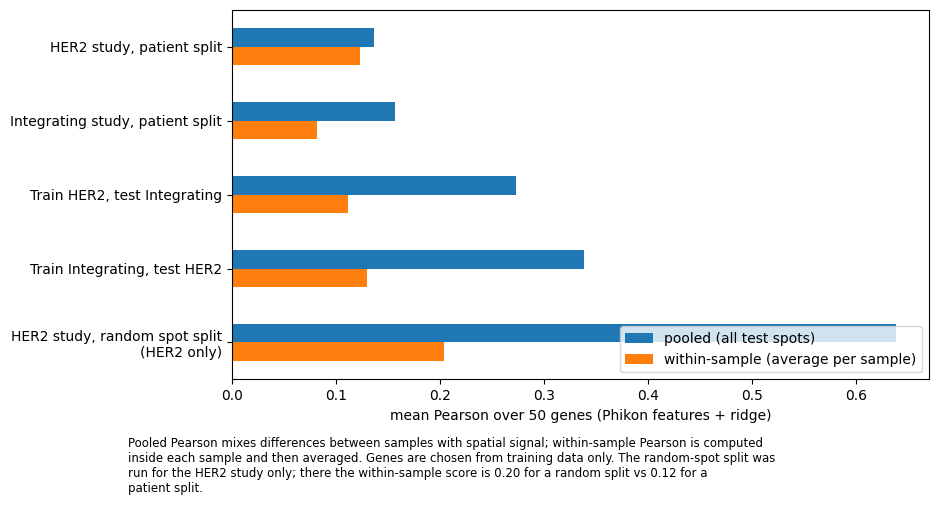

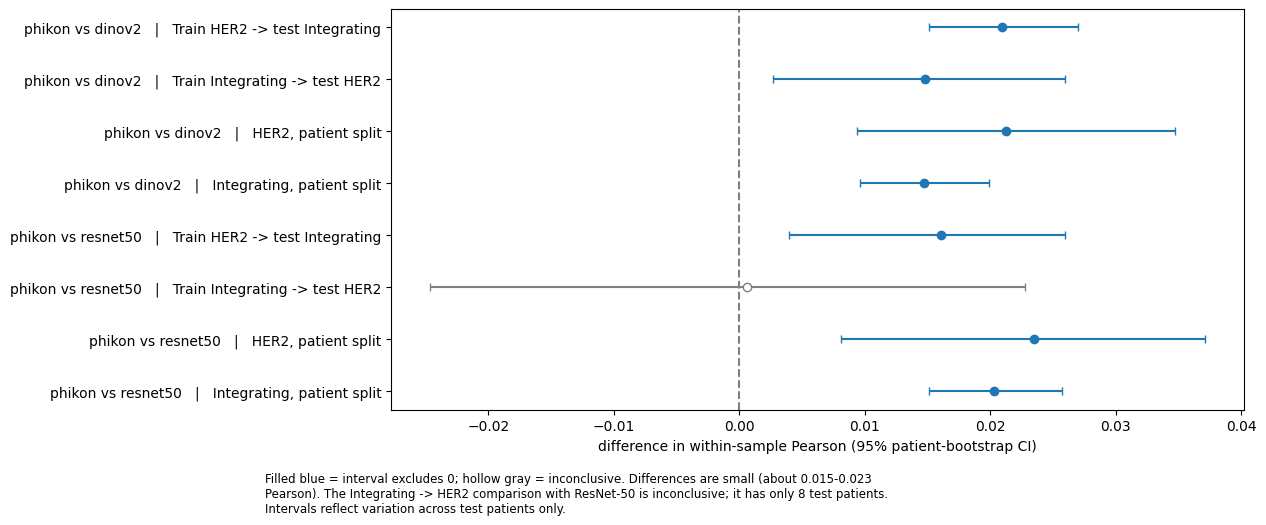

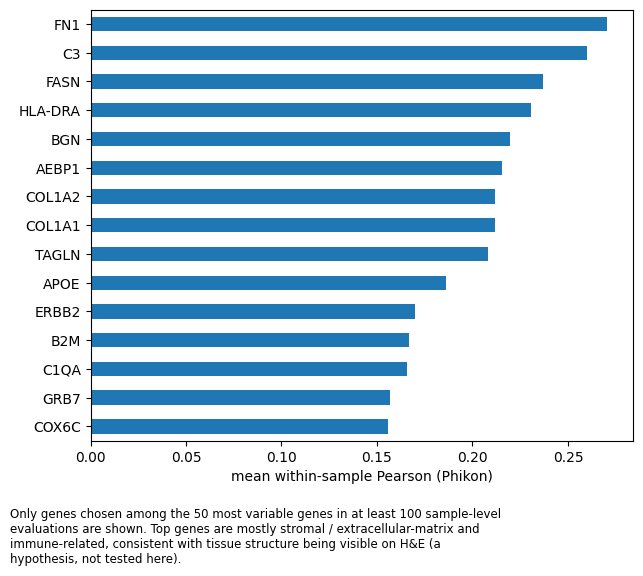

saved: ['captions.md', 'fig1_pooled_vs_within.png', 'fig2_model_differences.png', 'fig3_top_genes.png', 'fig4_spatial_best.png', 'fig4_spatial_median.png']


In [27]:
import os, textwrap
import numpy as np, pandas as pd, matplotlib.pyplot as plt

os.makedirs("/content/work/figures", exist_ok=True)
r2 = pd.read_csv("/content/work/results_v2_within.csv")
pg = pd.read_csv("/content/work/per_gene_within_sample.csv")
ci = pd.read_csv("/content/work/bootstrap_ci.csv")

def add_caption(fig, text, width=105):
    fig.text(0.01, -0.01, textwrap.fill(text, width), ha="left", va="top", fontsize=8.5)

def save(fig, name):
    fig.savefig(f"/content/work/figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

captions = {}

# ---------- Figure 1: pooled vs within-sample Pearson ----------
order = ["her2:patient_cv", "integrating:patient_cv", "cross_study:her2->integrating",
         "cross_study:integrating->her2", "her2:random_spot_cv"]
nice = {"her2:patient_cv": "HER2 study, patient split",
        "integrating:patient_cv": "Integrating study, patient split",
        "cross_study:her2->integrating": "Train HER2, test Integrating",
        "cross_study:integrating->her2": "Train Integrating, test HER2",
        "her2:random_spot_cv": "HER2 study, random spot split\n(HER2 only)"}
t = r2[r2.model == "phikon"].groupby("setting")[["pooled", "within"]].mean().reindex(order)
w_pat, w_rand = t.loc["her2:patient_cv", "within"], t.loc["her2:random_spot_cv", "within"]
t.index = [nice[i] for i in order]
t.columns = ["pooled (all test spots)", "within-sample (average per sample)"]

ax = t.plot.barh(figsize=(9, 4.8))
ax.invert_yaxis(); ax.set_ylabel("")
ax.set_xlabel("mean Pearson over 50 genes (Phikon features + ridge)")
ax.legend(loc="lower right")
cap1 = ("Pooled Pearson mixes differences between samples with spatial signal; within-sample Pearson is "
        "computed inside each sample and then averaged. Genes are chosen from training data only. "
        "The random-spot split was run for the HER2 study only; there the within-sample score is "
        f"{w_rand:.2f} for a random split vs {w_pat:.2f} for a patient split.")
add_caption(ax.figure, cap1); captions["fig1_pooled_vs_within"] = cap1
save(ax.figure, "fig1_pooled_vs_within")

# ---------- Figure 2: model differences with patient-bootstrap CIs ----------
lab = {"her2:patient_cv": "HER2, patient split",
       "integrating:patient_cv": "Integrating, patient split",
       "cross:her2->integrating": "Train HER2 -> test Integrating",
       "cross:integrating->her2": "Train Integrating -> test HER2"}
sub = ci[ci.comparison.isin(["phikon-resnet50", "phikon-dinov2"])].copy()
sub["name"] = sub["comparison"].str.replace("-", " vs ") + "   |   " + sub["setting"].map(lab)
sub = sub.sort_values(["comparison", "setting"]).reset_index(drop=True)
y = np.arange(len(sub))
excl0 = (sub.ci_low > 0) | (sub.ci_high < 0)

fig, ax = plt.subplots(figsize=(11, 5.2))
for i, r in sub.iterrows():
    ax.errorbar(r.mean_diff, i, xerr=[[r.mean_diff - r.ci_low], [r.ci_high - r.mean_diff]],
                fmt="o", capsize=3, color="C0" if excl0[i] else "gray",
                mfc="C0" if excl0[i] else "white")
ax.axvline(0, color="gray", ls="--"); ax.set_yticks(y); ax.set_yticklabels(sub["name"])
ax.invert_yaxis()
ax.set_xlabel("difference in within-sample Pearson (95% patient-bootstrap CI)")
cap2 = ("Filled blue = interval excludes 0; hollow gray = inconclusive. Differences are small "
        "(about 0.015-0.023 Pearson). The Integrating -> HER2 comparison with ResNet-50 is inconclusive; "
        "it has only 8 test patients. Intervals reflect variation across test patients only.")
add_caption(fig, cap2); captions["fig2_model_differences"] = cap2
save(fig, "fig2_model_differences")

# ---------- Figure 3: most predictable genes ----------
gg = pg[pg.model == "phikon"].groupby("gene")["r"].agg(["mean", "count"])
top = gg[gg["count"] >= 100].sort_values("mean", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 5.6))
top["mean"][::-1].plot.barh(ax=ax)
ax.set_xlabel("mean within-sample Pearson (Phikon)"); ax.set_ylabel("")
cap3 = ("Only genes chosen among the 50 most variable genes in at least 100 sample-level evaluations are shown. "
        "Top genes are mostly stromal / extracellular-matrix and immune-related, consistent with tissue "
        "structure being visible on H&E (a hypothesis, not tested here).")
add_caption(fig, cap3, width=80); captions["fig3_top_genes"] = cap3
save(fig, "fig3_top_genes")

with open("/content/work/figures/captions.md", "w") as f:
    for k, v in captions.items():
        f.write(f"**{k}**\n\n{v}\n\n")
print("saved:", sorted(os.listdir("/content/work/figures")))

## spatial maps for two held-out samples

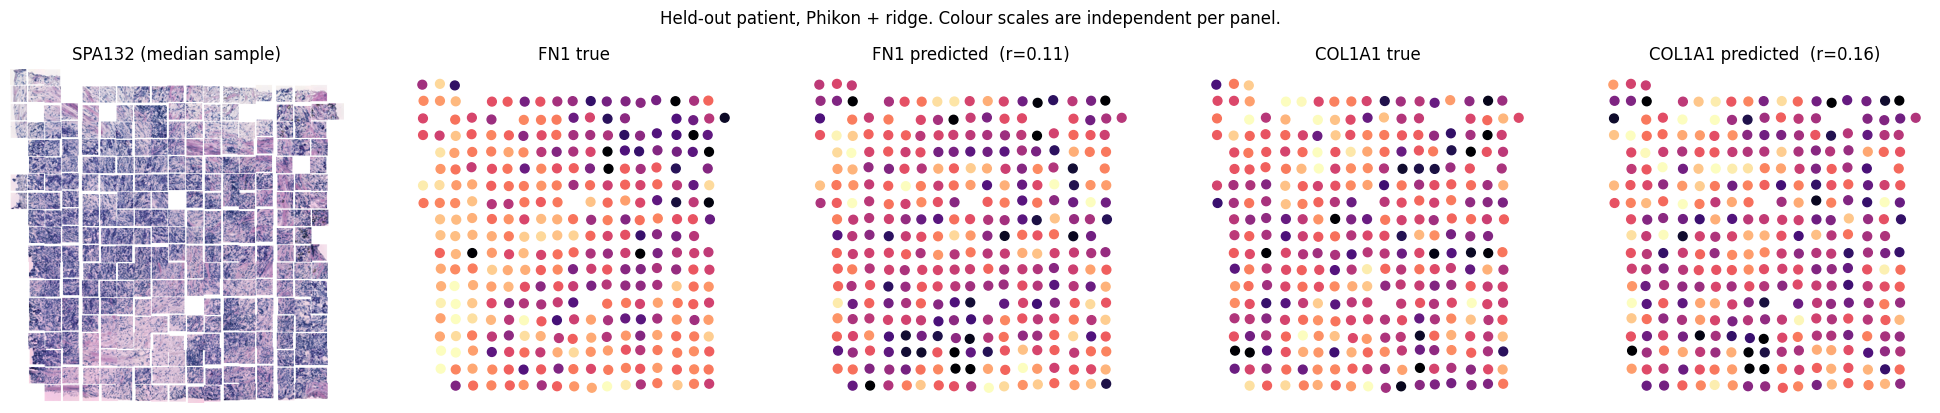

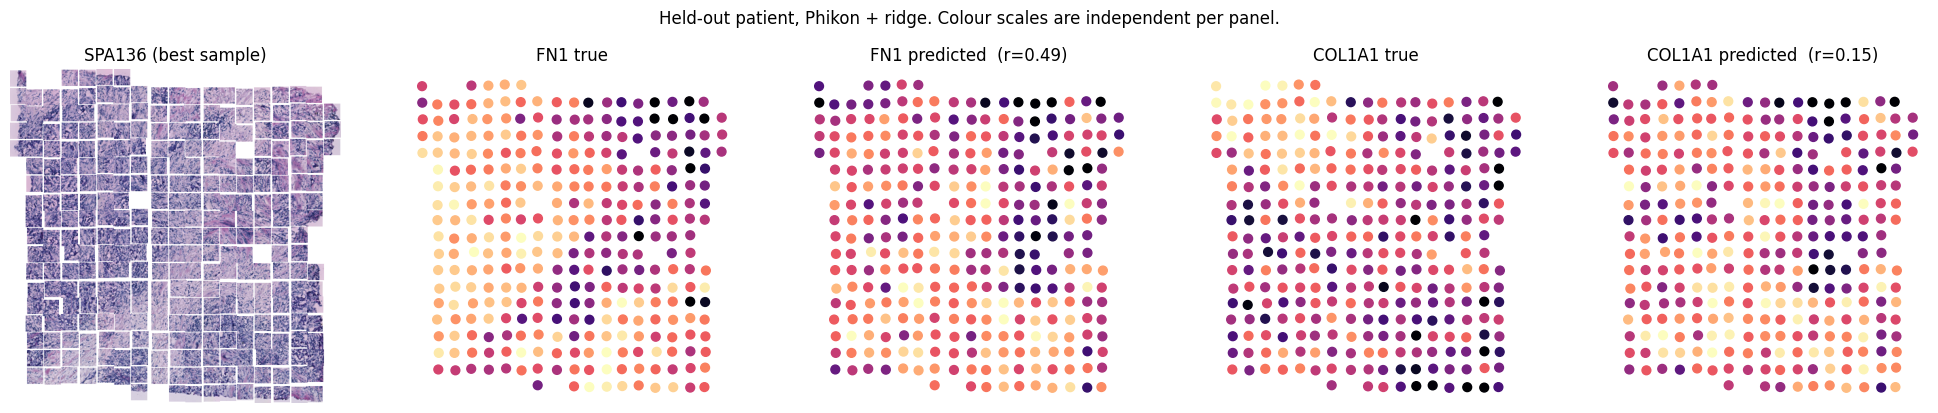

In [28]:
from scipy.spatial import cKDTree
from PIL import Image
import matplotlib.pyplot as plt, h5py

genes_show = ["FN1", "COL1A1"]
gi = [int(np.where(final == g)[0][0]) for g in genes_show]
Y = X[:, gi].toarray()

fn1 = (pg[(pg.setting == "her2:patient_cv") & (pg.model == "phikon") & (pg.gene == "FN1")]
       .groupby("id")["r"].mean().sort_values())
picks = {"median": fn1.index[len(fn1) // 2], "best": fn1.index[-1]}

def show_sample(sid, label, tile=24):
    g_out = spots.loc[spots["id"] == sid, "group"].iloc[0]
    tr = np.where((s == "her2") & (grp != g_out))[0]
    te = np.where(spots["id"].values == sid)[0]
    scaler = StandardScaler().fit(F["phikon"][tr])
    m = RidgeCV(alphas=[1e2, 1e3, 1e4, 1e5]).fit(scaler.transform(F["phikon"][tr]), Y[tr])
    P = m.predict(scaler.transform(F["phikon"][te]))

    rows = spots.iloc[te]
    a = sc.read_h5ad(f"/content/hest_data/st/{sid}.h5ad")
    xy = a[rows["barcode"].values].obsm["spatial"]
    with h5py.File(f"/content/hest_data/patches/{sid}.h5", "r") as f:
        imgs = f["img"][:][rows["patch_idx"].values]

    d = np.median(cKDTree(xy).query(xy, k=2)[0][:, 1])
    pos = ((xy - xy.min(0)) * (tile / d)).astype(int)
    canvas = np.full((pos[:, 1].max() + tile, pos[:, 0].max() + tile, 3), 255, np.uint8)
    for (x, y), im in zip(pos, imgs):
        canvas[y:y+tile, x:x+tile] = np.array(Image.fromarray(im).resize((tile, tile)))

    fig, axes = plt.subplots(1, 1 + 2 * len(gi), figsize=(4 * (1 + 2 * len(gi)), 4))
    axes[0].imshow(canvas); axes[0].axis("off"); axes[0].set_title(f"{sid} ({label} sample)")
    for k, g in enumerate(genes_show):
        yt, yp = Y[te, k], P[:, k]
        r = np.corrcoef(yt, yp)[0, 1]
        for j, (v, name) in enumerate([(yt, "true"), (yp, "predicted")]):
            ax = axes[1 + 2 * k + j]
            ax.scatter(xy[:, 0], xy[:, 1], c=v, s=40, cmap="magma",
                       vmin=np.percentile(v, 2), vmax=np.percentile(v, 98))
            ax.invert_yaxis(); ax.set_aspect("equal"); ax.axis("off")
            ax.set_title(f"{g} {name}" + (f"  (r={r:.2f})" if j == 1 else ""))
    plt.suptitle("Held-out patient, Phikon + ridge. Colour scales are independent per panel.", y=1.02)
    plt.tight_layout()
    plt.savefig(f"/content/work/figures/fig4_spatial_{label}.png", dpi=200, bbox_inches="tight")
    plt.show()

for label, sid in picks.items():
    show_sample(sid, label)